In [1]:
# Importing libraries required for Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Setting visualization style and display options
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Loading all three Titanic CSV files

train = pd.read_csv(r"C:\Users\mudas\OneDrive\Documents\Data_Analyst-Internship\Task-5\titanic\train.csv")
test = pd.read_csv(r"C:\Users\mudas\OneDrive\Documents\Data_Analyst-Internship\Task-5\titanic\test.csv")
gender_submission = pd.read_csv(r"C:\Users\mudas\OneDrive\Documents\Data_Analyst-Internship\Task-5\titanic\gender_submission.csv")

# Displaying the first five records
print("Training Dataset:")
display(train.head())

print("Testing Dataset:")
display(test.head())

print("Gender Submission Dataset:")
display(gender_submission.head())


Training Dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Testing Dataset:


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


Gender Submission Dataset:


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [3]:

# Checking the number of rows and columns in each dataset

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)
print("Gender Submission Shape:", gender_submission.shape)


Training Dataset Shape: (891, 12)
Testing Dataset Shape: (418, 11)
Gender Submission Shape: (418, 2)


In [4]:

# Understanding column names, data types and non-null values

print("TRAINING DATASET INFORMATION")
train.info()

print("\nTESTING DATASET INFORMATION")
test.info()

print("\nCOLUMN NAMES:")
print(train.columns.tolist())


TRAINING DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

TESTING DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----

In [5]:

# Generating descriptive statistics for numerical columns

print("Statistical Summary:")
display(train.describe())

# Summary of categorical columns
print("Categorical Data Summary:")
display(train.describe(include='object'))


Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Categorical Data Summary:


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [6]:

# Identifying missing values in the training dataset

print("Missing Values in Each Column:")
display(train.isnull().sum())

# Calculating missing value percentages
missing_percentage = (train.isnull().sum() / len(train)) * 100

print("\nMissing Value Percentage:")
display(missing_percentage[missing_percentage > 0])

# Checking duplicate records
print("\nNumber of Duplicate Records:", train.duplicated().sum())


Missing Values in Each Column:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Missing Value Percentage:


Age         19.865320
Cabin       77.104377
Embarked     0.224467
dtype: float64


Number of Duplicate Records: 0


In [7]:

# Analyzing frequency distributions of categorical variables

print("Passenger Gender Distribution:")
display(train['Sex'].value_counts())

print("\nPassenger Class Distribution:")
display(train['Pclass'].value_counts())

print("\nEmbarkation Port Distribution:")
display(train['Embarked'].value_counts())

print("\nSurvival Distribution:")
display(train['Survived'].value_counts())

print("\nSurvival Percentage:")
display(train['Survived'].value_counts(normalize=True) * 100)


Passenger Gender Distribution:


Sex
male      577
female    314
Name: count, dtype: int64


Passenger Class Distribution:


Pclass
3    491
1    216
2    184
Name: count, dtype: int64


Embarkation Port Distribution:


Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


Survival Distribution:


Survived
0    549
1    342
Name: count, dtype: int64


Survival Percentage:


Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [8]:

# Creating a working copy to preserve the original dataset

df = train.copy()

# Handling missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Extracting passenger title from names
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.')

# Creating family size and solo traveler features
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# Extracting cabin deck
df['Deck'] = df['Cabin'].str[0].fillna('Unknown')

print("Data cleaning and feature engineering completed!")

print("\nMissing Values After Cleaning:")
display(df.isnull().sum())

print("\nUpdated Dataset:")
display(df.head())


Data cleaning and feature engineering completed!

Missing Values After Cleaning:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Title            0
FamilySize       0
IsAlone          0
Deck             0
dtype: int64


Updated Dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,FamilySize,IsAlone,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,2,0,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,2,0,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss,1,1,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,2,0,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr,1,1,Unknown


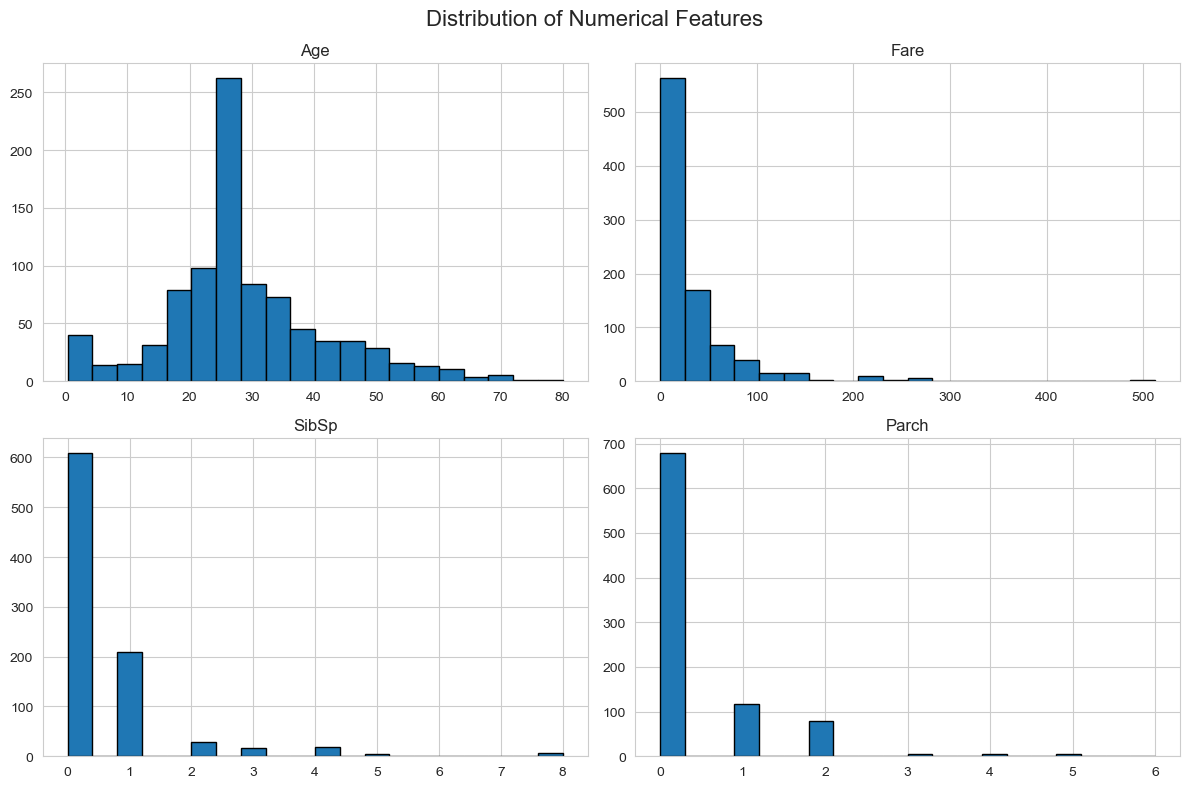

In [9]:

# Visualizing distributions of numerical variables using histograms

numerical_columns = ['Age', 'Fare', 'SibSp', 'Parch']

df[numerical_columns].hist(
    bins=20,
    figsize=(12, 8),
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()


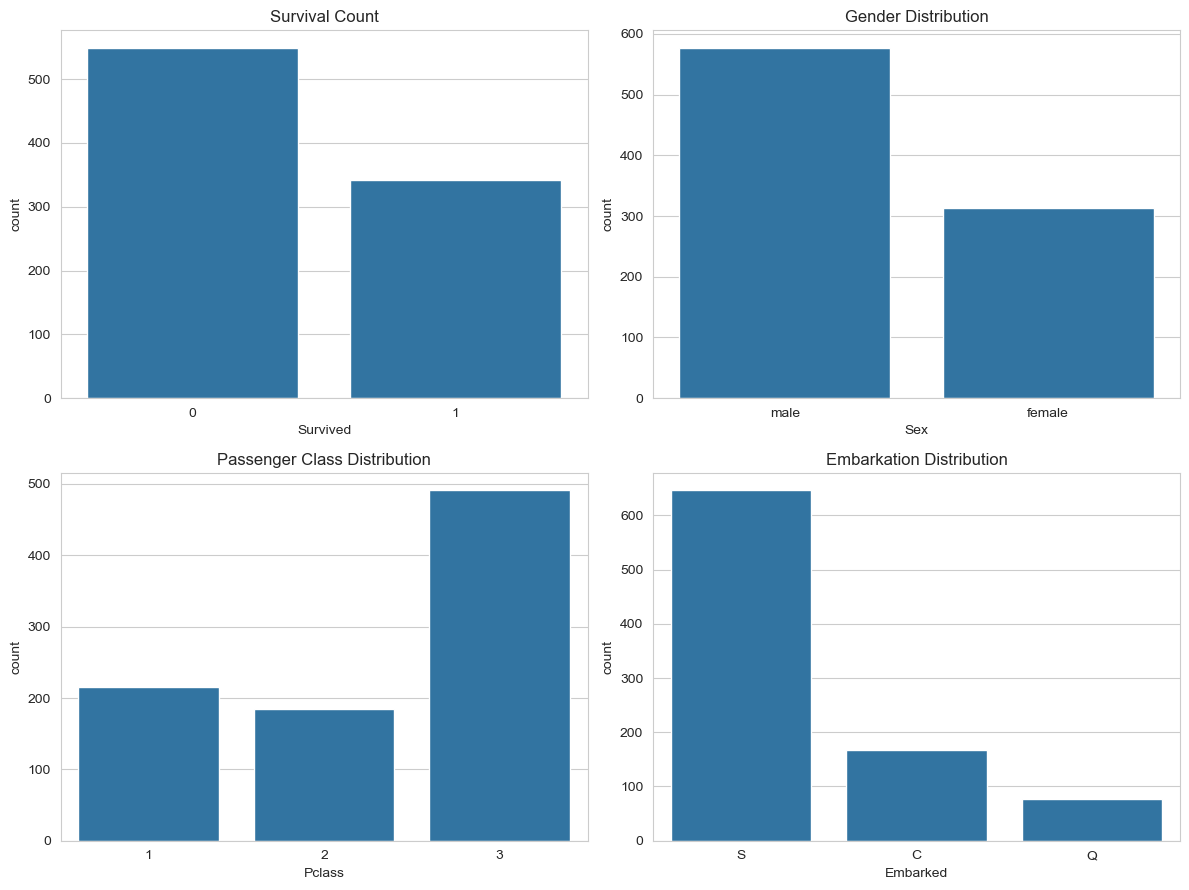

In [10]:

# Visualizing categorical variable distributions

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.countplot(data=df, x='Survived', ax=axes[0, 0])
axes[0, 0].set_title('Survival Count')

sns.countplot(data=df, x='Sex', ax=axes[0, 1])
axes[0, 1].set_title('Gender Distribution')

sns.countplot(data=df, x='Pclass', ax=axes[1, 0])
axes[1, 0].set_title('Passenger Class Distribution')

sns.countplot(data=df, x='Embarked', ax=axes[1, 1])
axes[1, 1].set_title('Embarkation Distribution')

plt.tight_layout()
plt.show()


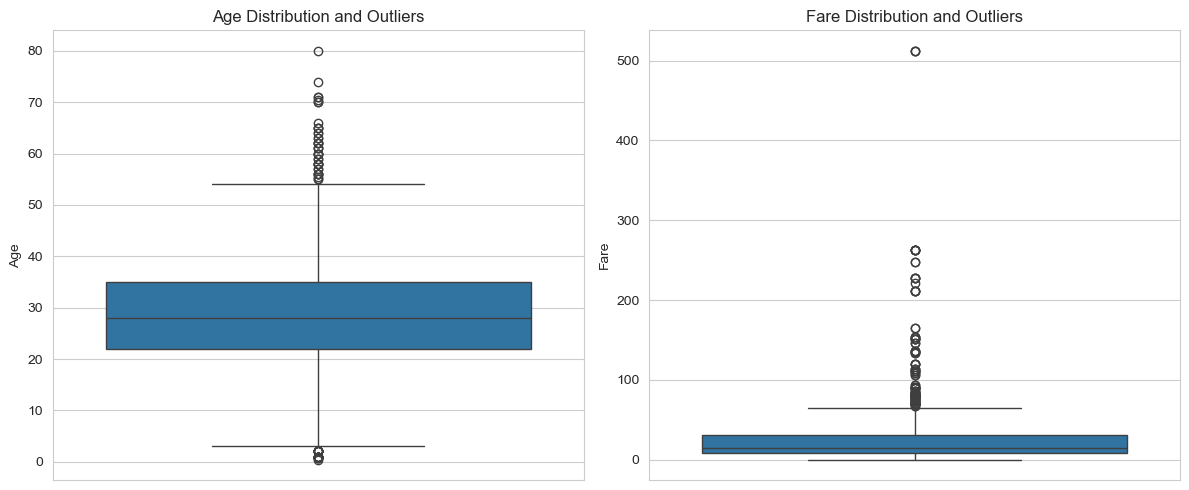

In [11]:

# Detecting potential outliers using boxplots

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, y='Age', ax=axes[0])
axes[0].set_title('Age Distribution and Outliers')

sns.boxplot(data=df, y='Fare', ax=axes[1])
axes[1].set_title('Fare Distribution and Outliers')

plt.tight_layout()
plt.show()


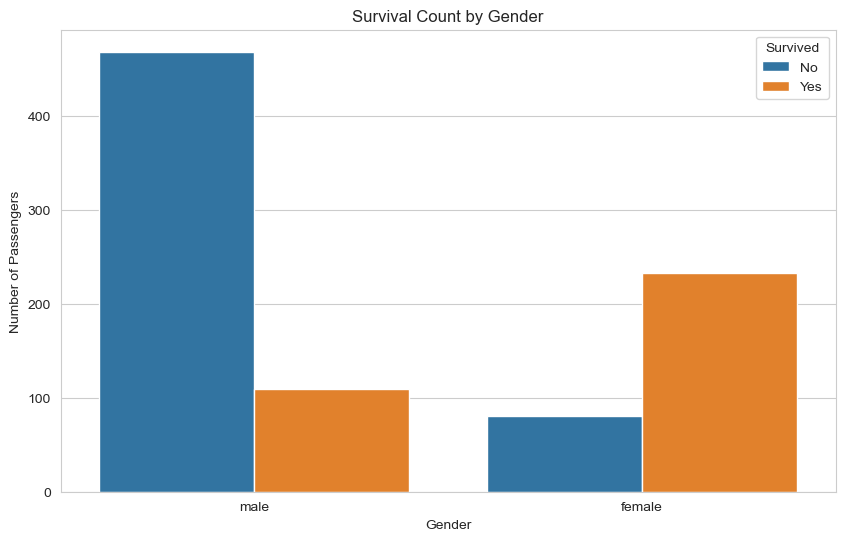

Survived,0,1
Sex,,
female,25.796178,74.203822
male,81.109185,18.890815


In [12]:

# Examining the relationship between passenger gender and survival

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title('Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

# Calculating survival percentages by gender
display(pd.crosstab(df['Sex'], df['Survived'], normalize='index') * 100)


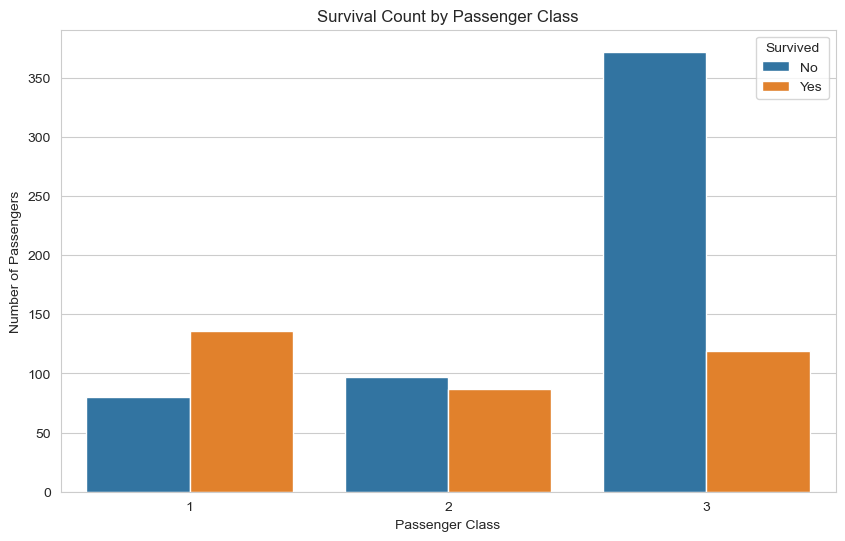

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


In [13]:

# Analyzing survival patterns across passenger classes

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title('Survival Count by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

# Survival percentage by passenger class
display(pd.crosstab(df['Pclass'], df['Survived'], normalize='index') * 100)


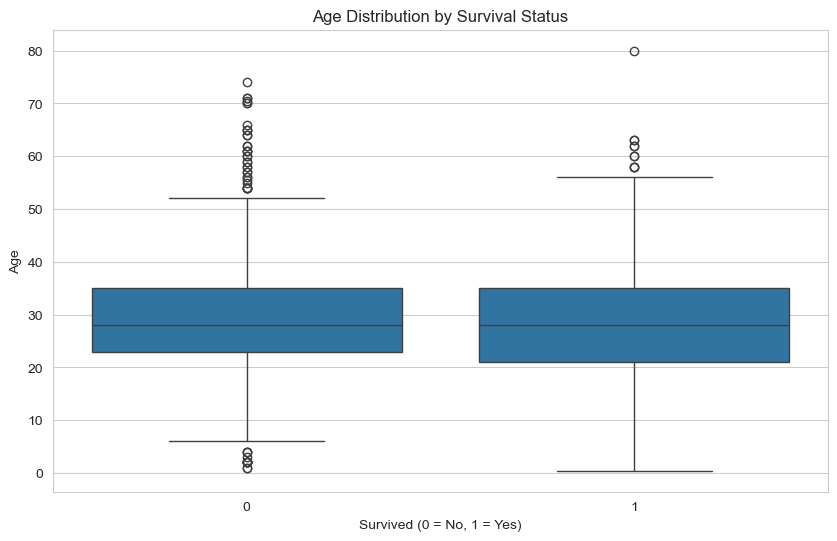

In [14]:

# Comparing passenger age distributions based on survival status

sns.boxplot(data=df, x='Survived', y='Age')

plt.title('Age Distribution by Survival Status')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Age')
plt.show()


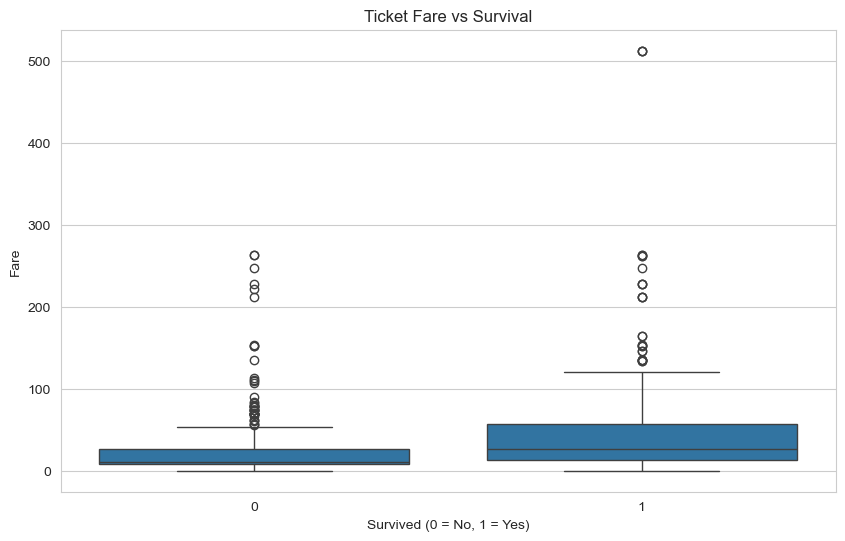

In [15]:

# Comparing ticket fare distributions based on survival status

sns.boxplot(data=df, x='Survived', y='Fare')

plt.title('Ticket Fare vs Survival')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Fare')
plt.show()


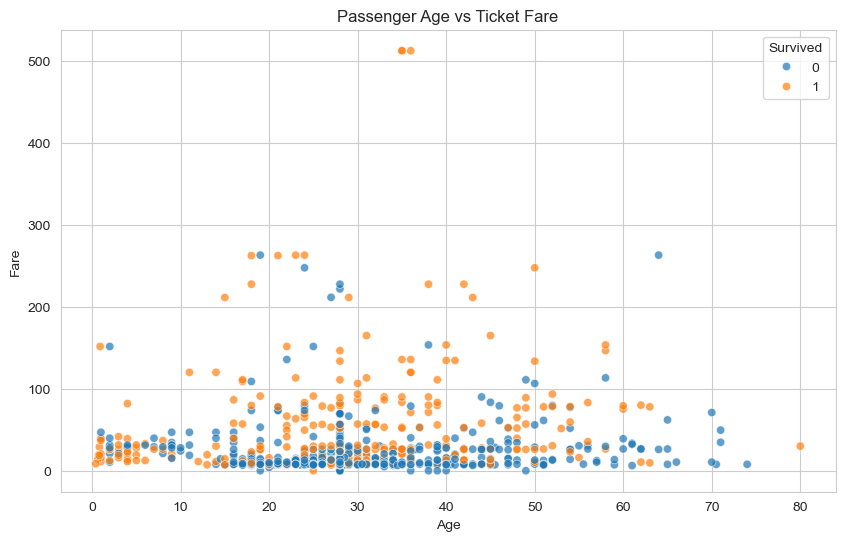

In [16]:

# Examining the relationship between passenger age and ticket fare

sns.scatterplot(
    data=df,
    x='Age',
    y='Fare',
    hue='Survived',
    alpha=0.7
)

plt.title('Passenger Age vs Ticket Fare')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.legend(title='Survived')
plt.show()


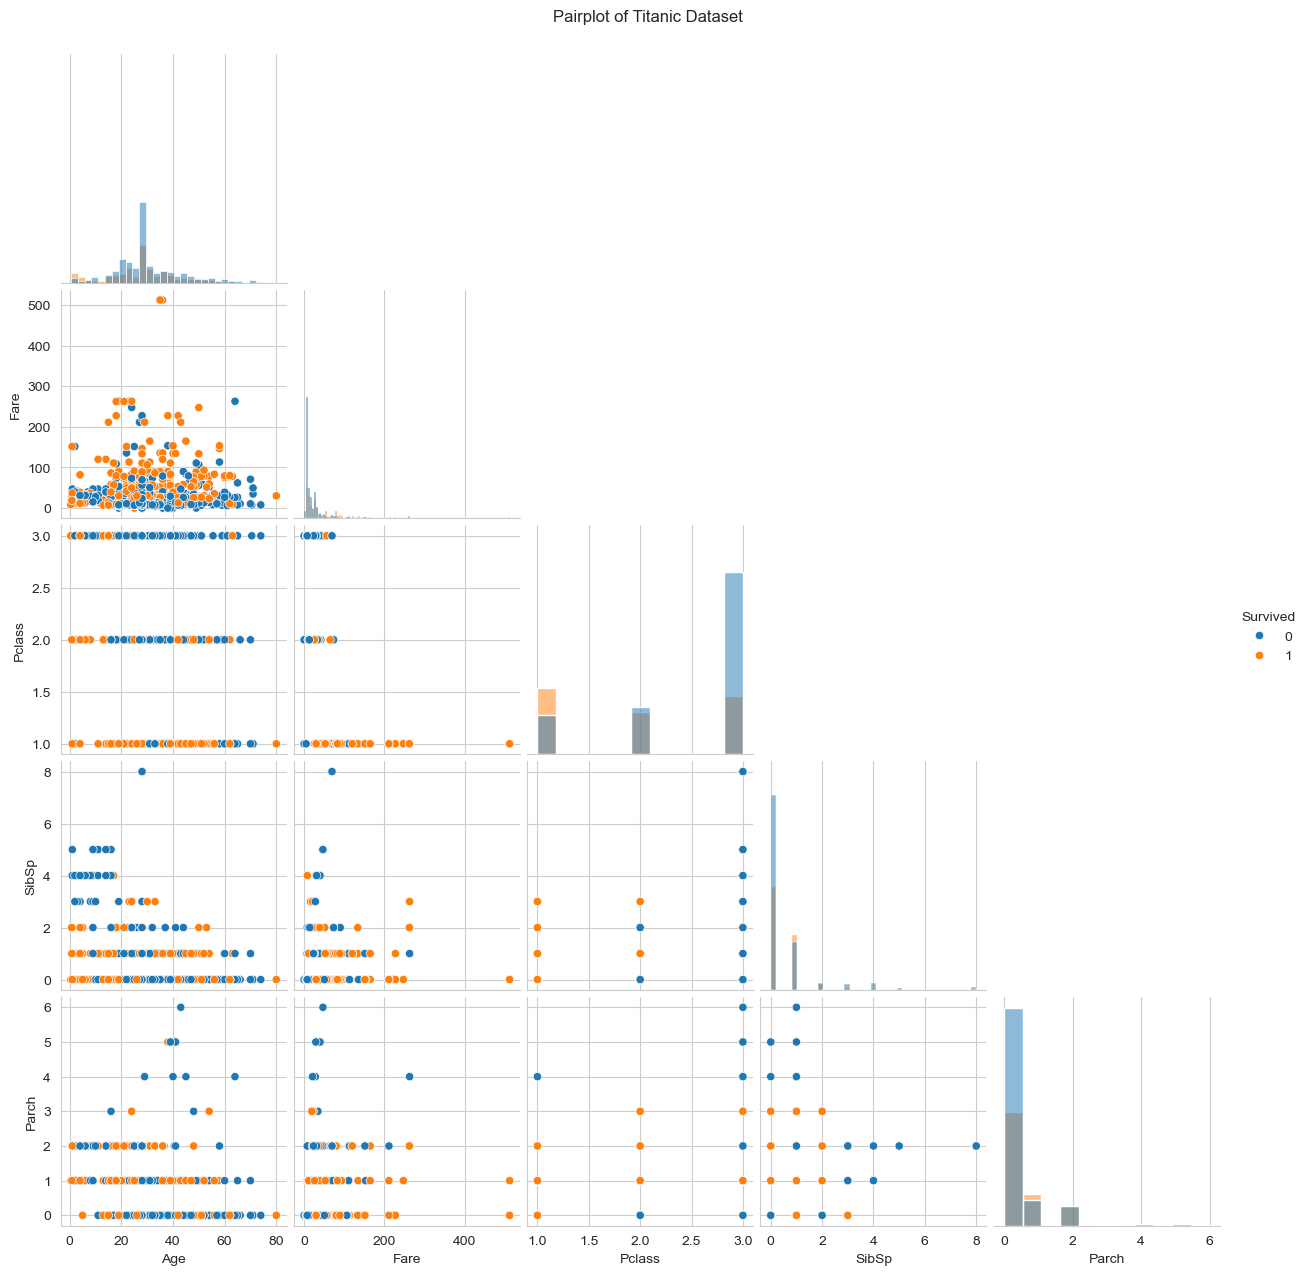

In [17]:

# Visualizing relationships among multiple numerical variables

pairplot_data = df[
    ['Survived', 'Age', 'Fare', 'Pclass', 'SibSp', 'Parch']
]

sns.pairplot(
    pairplot_data,
    hue='Survived',
    diag_kind='hist',
    corner=True
)

plt.suptitle('Pairplot of Titanic Dataset', y=1.02)
plt.show()


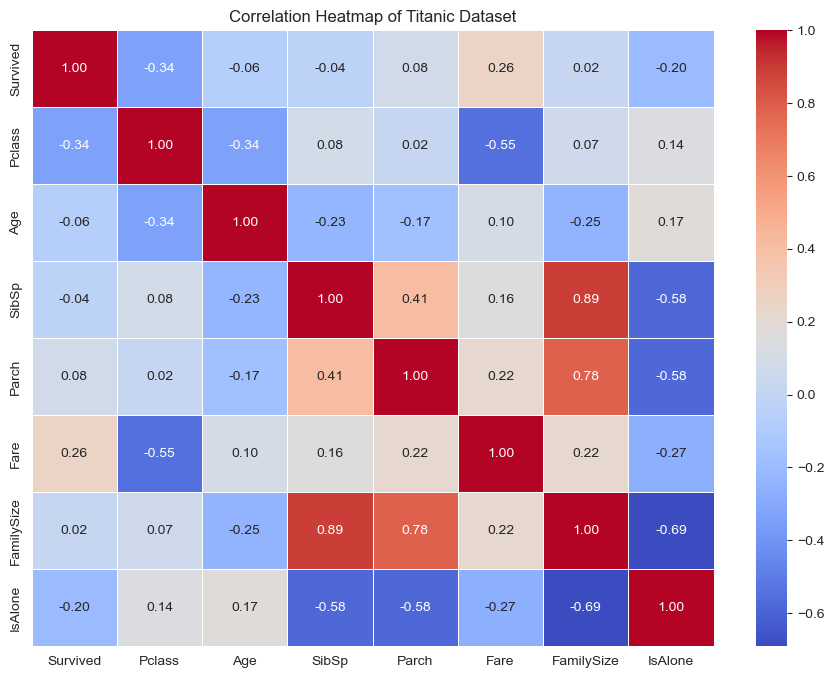

In [18]:

# Calculating correlations between numerical variables

correlation = df[
    ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
].corr()

# Visualizing the correlation matrix
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Titanic Dataset')
plt.show()


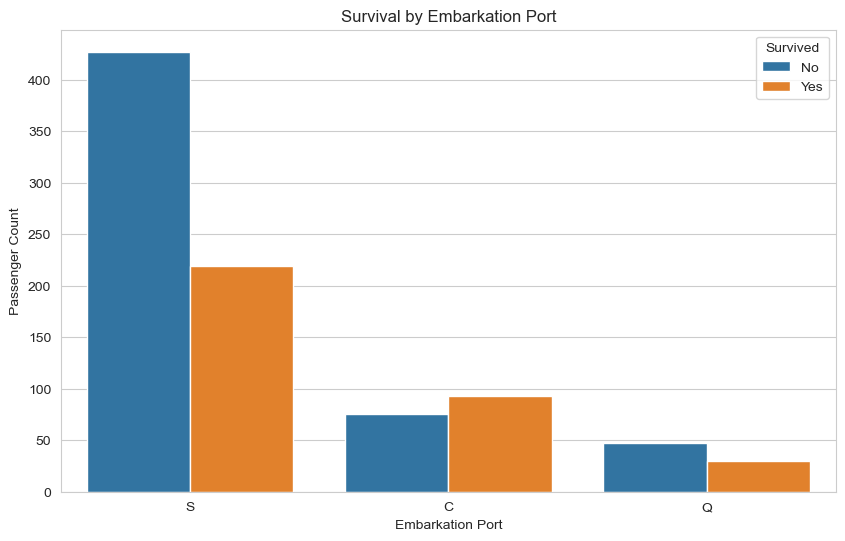

Survived,0,1
Embarked,,
C,44.642857,55.357143
Q,61.038961,38.961039
S,66.099071,33.900929


In [19]:

# Studying survival patterns across different embarkation ports

sns.countplot(data=df, x='Embarked', hue='Survived')

plt.title('Survival by Embarkation Port')
plt.xlabel('Embarkation Port')
plt.ylabel('Passenger Count')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()

display(pd.crosstab(df['Embarked'], df['Survived'], normalize='index') * 100)


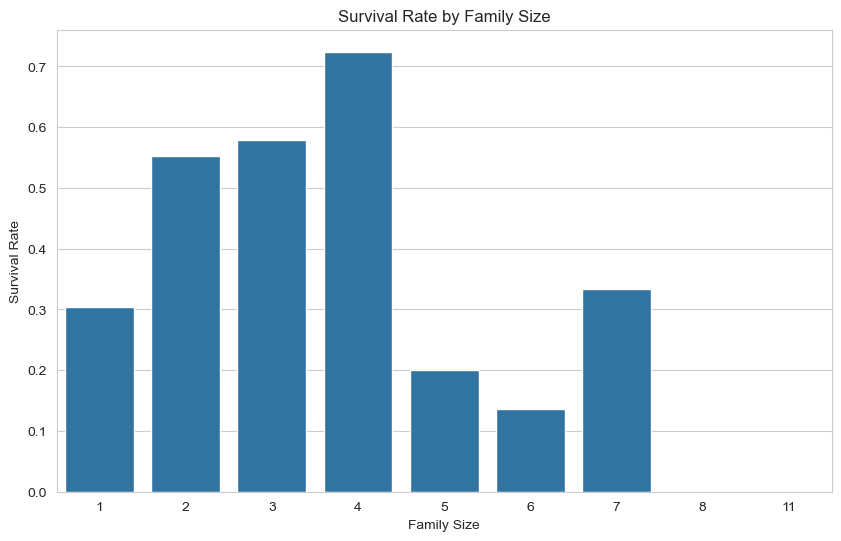

IsAlone
0    50.564972
1    30.353818
Name: Survived, dtype: float64

In [20]:

# Investigating the relationship between family size and survival

sns.barplot(data=df, x='FamilySize', y='Survived', errorbar=None)

plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.show()

# Average survival rate for solo and family travelers
display(df.groupby('IsAlone')['Survived'].mean() * 100)


Skewness of Numerical Features:


Age           0.510245
Fare          4.787317
SibSp         3.695352
Parch         2.749117
FamilySize    2.727441
dtype: float64

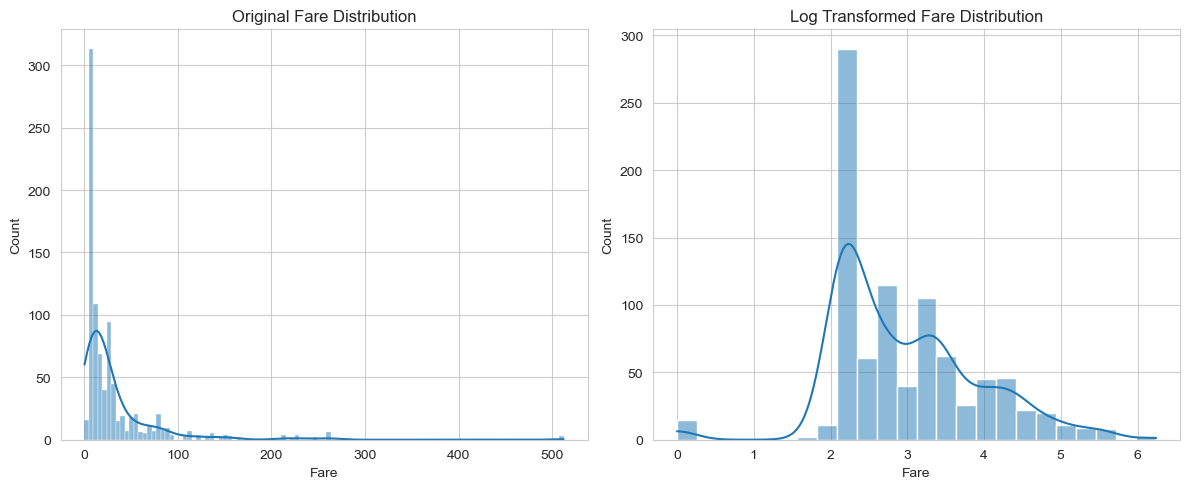

In [21]:

# Measuring skewness in numerical variables

skewness = df[
    ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize']
].skew()

print("Skewness of Numerical Features:")
display(skewness)

# Visualizing the distribution of Fare before and after log transformation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['Fare'], kde=True, ax=axes[0])
axes[0].set_title('Original Fare Distribution')

sns.histplot(np.log1p(df['Fare']), kde=True, ax=axes[1])
axes[1].set_title('Log Transformed Fare Distribution')

plt.tight_layout()
plt.show()


In [22]:

# Generating important findings from the Titanic dataset

total_passengers = len(df)
survived = df['Survived'].sum()
not_survived = total_passengers - survived

survival_rate = (survived / total_passengers) * 100

gender_survival = df.groupby('Sex')['Survived'].mean() * 100
class_survival = df.groupby('Pclass')['Survived'].mean() * 100

print("========== TITANIC EDA SUMMARY ==========")

print("\nTotal Passengers:", total_passengers)
print("Passengers Survived:", survived)
print("Passengers Not Survived:", not_survived)

print(f"\nOverall Survival Rate: {survival_rate:.2f}%")

print("\nSurvival Rate by Gender:")
display(gender_survival)

print("\nSurvival Rate by Passenger Class:")
display(class_survival)

print("\nAverage Passenger Age:", round(df['Age'].mean(), 2))
print("Average Ticket Fare:", round(df['Fare'].mean(), 2))

print("\nRemaining Missing Values:", df.isnull().sum().sum())

print("\nEDA COMPLETED SUCCESSFULLY!")


========== TITANIC EDA SUMMARY ==========

Total Passengers: 891
Passengers Survived: 342
Passengers Not Survived: 549

Overall Survival Rate: 38.38%

Survival Rate by Gender:


Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


Survival Rate by Passenger Class:


Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


Average Passenger Age: 29.36
Average Ticket Fare: 32.2

Remaining Missing Values: 687

EDA COMPLETED SUCCESSFULLY!


In [23]:

# Exporting the cleaned Titanic dataset for future use

df.to_csv('titanic_cleaned.csv', index=False)

print("Cleaned dataset saved successfully as titanic_cleaned.csv")


Cleaned dataset saved successfully as titanic_cleaned.csv


In [24]:

# Generating a PDF report containing EDA findings

from matplotlib.backends.backend_pdf import PdfPages

with PdfPages('Titanic_EDA_Report.pdf') as pdf:

    # Page 1: Report overview
    fig = plt.figure(figsize=(11, 8.5))
    plt.axis('off')

    report_text = f"""
    TITANIC DATASET
    EXPLORATORY DATA ANALYSIS REPORT

    Project Objective:
    To explore passenger data and identify patterns,
    relationships, trends and anomalies.

    Dataset Overview:
    Total Passengers: {total_passengers}
    Total Features: {train.shape[1]}
    Passengers Survived: {survived}
    Passengers Not Survived: {not_survived}

    Overall Survival Rate: {survival_rate:.2f}%

    Average Passenger Age: {df['Age'].mean():.2f}
    Average Ticket Fare: {df['Fare'].mean():.2f}

    Data Cleaning:
    - Missing Age values handled using median.
    - Missing Embarked values handled using mode.
    - Missing Fare values handled using median.
    - Created FamilySize, IsAlone and Title features.
    """

    plt.text(0.08, 0.9, report_text, fontsize=13,
             verticalalignment='top', linespacing=1.7)

    pdf.savefig(fig, bbox_inches='tight')
    plt.close()

    # Page 2: Key analytical findings
    fig = plt.figure(figsize=(11, 8.5))
    plt.axis('off')

    findings = f"""
    KEY EDA FINDINGS

    1. Survival Analysis:
       Overall survival rate was {survival_rate:.2f}%.

    2. Gender Analysis:
       Female survival rate: {gender_survival.get('female', 0):.2f}%
       Male survival rate: {gender_survival.get('male', 0):.2f}%

    3. Passenger Class Analysis:
       First class survival: {class_survival.get(1, 0):.2f}%
       Second class survival: {class_survival.get(2, 0):.2f}%
       Third class survival: {class_survival.get(3, 0):.2f}%

    4. Statistical Analysis:
       Histograms were used to study distributions.
       Boxplots helped identify potential outliers.
       Scatterplots examined variable relationships.

    5. Multivariate Analysis:
       Pairplots and correlation heatmaps were
       used to explore relationships between variables.

    CONCLUSION

    The analysis revealed differences in survival
    patterns based on passenger gender and class.
    Data visualization and statistical methods helped
    identify important patterns in the Titanic dataset.

    Tools Used:
    Python, Pandas, NumPy, Matplotlib and Seaborn.
    """

    plt.text(0.08, 0.9, findings, fontsize=12,
             verticalalignment='top', linespacing=1.7)

    pdf.savefig(fig, bbox_inches='tight')
    plt.close()

print("PDF report generated successfully!")
print("File: Titanic_EDA_Report.pdf")


PDF report generated successfully!
File: Titanic_EDA_Report.pdf
